# Practical 1 : integrating single-cell and spatial analyses in python
In this practical, you will consecutively analyse single-cell (10X genomics chromium) and spatial transcriptomics (10X genomics Visium) from a pleural mesothelioma tumor.

We will focus on a single donor, patient 3B, a 80+ y.o. male without asbestos exposure on which 1 single-cell and 1 spatial sequencing were performed.

## Part II: spatial analyses and cell-cell communication
In the second part of the practical, you will explore spatial expression patterns, determine spatial domains and infer significant cell-cell interactions from single-cell and spatial datasets.

The data was already processed (see scripts in files/data/Practical1/S/scripts/), with QC and filtering of cells and features and normalization. You can find an example of basic spatial data processing in a scanpy tutorial: https://scanpy.readthedocs.io/en/stable/tutorials/basics/clustering.html      
Spatial deconvolution with a scRNA-seq reference was already performed with cell2location method. This step is too computationally demanding to include in this practical, but you can find a tutorial on spatial deconvolution here: https://www.sc-best-practices.org/spatial/deconvolution.html

For the analysys steps we will mostly use the squidpy package. Similarly to the scanpy module, squidpy has submodules gr for graph analyses (e.g., computing nearest neighbors and graph metrics), pl for plotting functions, and tl for tools, as well as im for image analyses. See documentation (https://squidpy.readthedocs.io/en/stable/api.html) for further details on functions and arguments.

### Loading modules

In [1]:
import squidpy as sq
import scanpy as sc
import liana as li
import os

/home/delhommet/miniconda3/envs/MG_sc_env/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/delhommet/miniconda3/envs/MG_sc_env/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/delhommet/miniconda3/envs/MG_sc_env/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(ms

In [2]:
sc.settings.verbosity = 3
sc.settings.set_figure_params(dpi=80, facecolor="white")

### Loading data  

Q1. Load the ST dataset (10X Visium sample from a pleural mesothelioma tumor). You may use scanpy to read the anndata object. 

In [3]:
# load spatial data with cell-type deconvolution 

ddir = os.path.join("/data/", "Training-MG/files/data/Practical1/ST/2026")

adata_st = sc.read(os.path.join(ddir, "sample3B_visium_deconvoluted.h5ad") )


### Overview of the data  

Q2. Explore the loaded anndata object. How many spots and features (genes) it contains? Can you access raw and log-normalised counts? Where the deconvolution results are stored?

In [4]:
# Print a compact overview of the AnnData object
print(adata_st) # 819 spots & 11813 features

# Number of spots and genes
print("Number of spots:", adata_st.n_obs)
print("Number of genes/features:", adata_st.n_vars)

# Inspect spot-level metadata
print(adata_st.obs.head())

# Inspect gene-level metadata
print(adata_st.var.head())

# Inspect available expression matrices
print("Layers:", adata_st.layers.keys()) # normalized counts: adata_st.layers["log1p_norm"]
print("Obsm:", adata_st.obsm.keys()) # deconvolution results stored in adata_st.obsm, a matrix of estimated cell-type abundances/proportions per spot
print("Uns:", adata_st.uns.keys())

AnnData object with n_obs × n_vars = 819 × 11813
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'cluster', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'outlier', 'mt_outlier', '_indices', '_scvi_batch', '_scvi_labels', 'B cells', 'DC', 'ILC', 'Macrophages', 'Monocytes', 'T cells', 'pDC', 'epi/mesothelial', 'endothelial', 'stromal', 'tumor'
    var: 'feature_types', 'genome', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'feature_name'
    uns: '_scvi_manager_uuid', '_scvi

Q3. Plot the QC metrics (number of genes expressed per spot, total number of counts per spot and the percentage of mitochondrial gene expression) for this dataset. You may use violin plot from scanpy. 

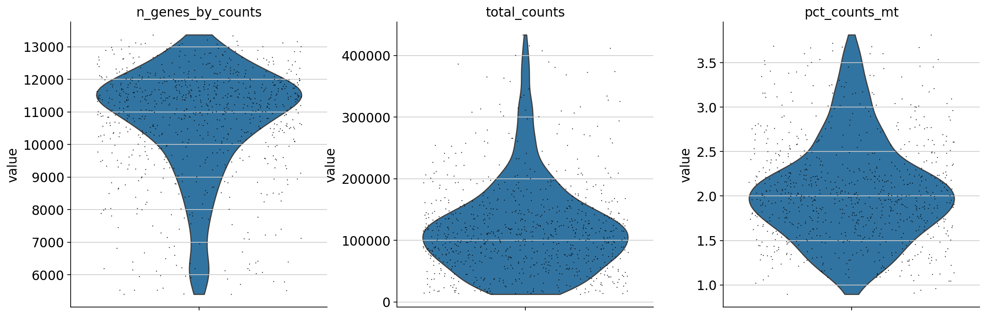

In [5]:
#violin plots of QC metrics

sc.pl.violin(
    adata_st,
    keys=[
        "n_genes_by_counts",
        "total_counts",
        "pct_counts_mt"
    ],
    jitter=0.4,
    multi_panel=True
)


Q4. Visualize clusters (maybe not), number of genes expressed per spot and total number of counts per spot on a spatial plot using sq.pl.spatial_scatter(). Note the heterogeneity in gene expression over the Visium sample.

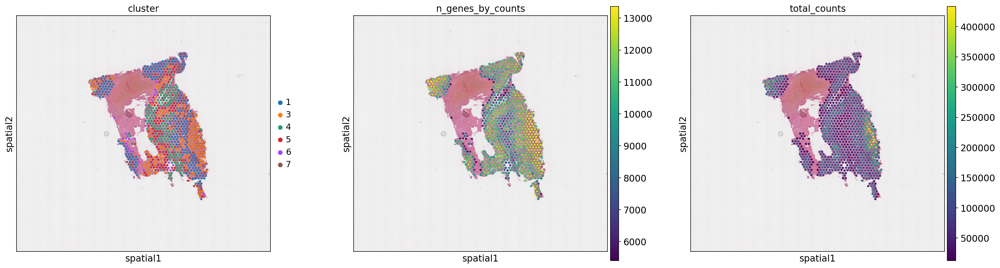

In [6]:
adata_st.obs["cluster"] = adata_st.obs["cluster"].astype("category")

# Plot cluster labels, gene complexity, and total counts in space
sq.pl.spatial_scatter(
    adata_st,
    color=[
        "cluster",
        "n_genes_by_counts",
        "total_counts"
    ],
    figsize=(7, 7),
    ncols=3
)

Q5. Visualize spatial expression of some of the highly variable genes. Do they present any spatial pattern?

Selected HVGs:
['SAMD11', 'HES4', 'ISG15', 'AGRN', 'TNFRSF18', 'TNFRSF4', 'MXRA8', 'VWA1']


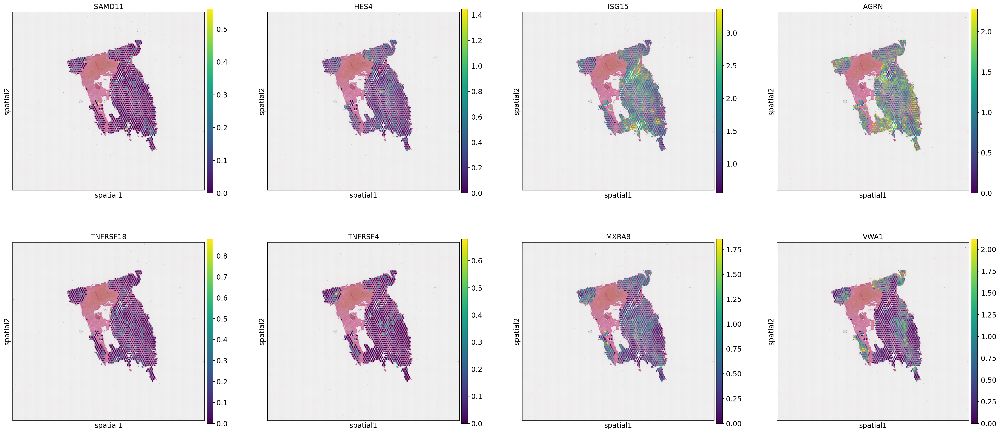

In [7]:
# Select the first highly variable genes
hvg = adata_st.var_names[adata_st.var["highly_variable"]][:8].tolist()

print("Selected HVGs:")
print(hvg)

# Visualize their spatial expression
sq.pl.spatial_scatter(
    adata_st,
    color=hvg,
    layer="log1p_norm",
    figsize=(7, 7),
    ncols=4
)

Q6. Visualize the proportions of some cell types on the spatial slide (tumor, stromal, mesothelial, some immune cell type). Do they occupy different locations on the spatial slide? 

OBS columns:
['in_tissue', 'array_row', 'array_col', 'sample', 'cluster', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'outlier', 'mt_outlier', '_indices', '_scvi_batch', '_scvi_labels', 'B cells', 'DC', 'ILC', 'Macrophages', 'Monocytes', 'T cells', 'pDC', 'epi/mesothelial', 'endothelial', 'stromal', 'tumor']

OBSM keys:
KeysView(AxisArrays with keys: MT, means_cell_abundance_w_sf, q05_cell_abundance_w_sf, q95_cell_abundance_w_sf, spatial, stds_cell_abundance_w_sf)

Layers:
KeysView(Layers with keys: counts, log1p_norm)


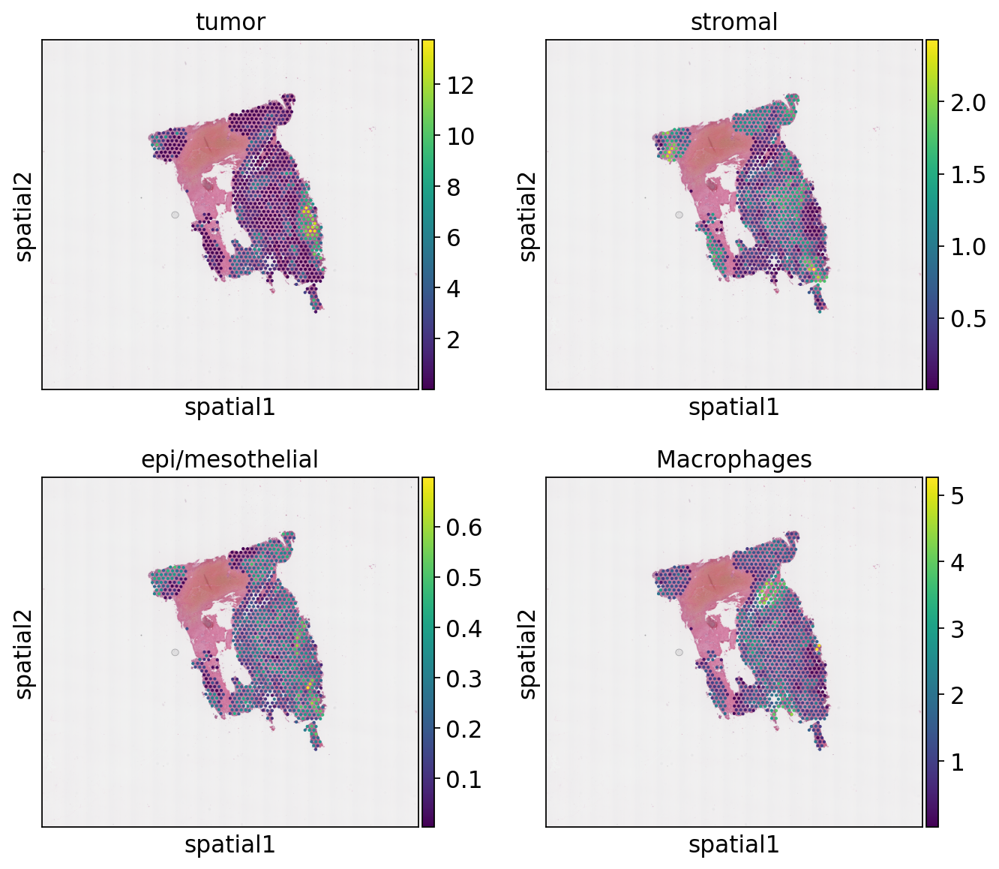

In [9]:
# To inspect the AnnData object
# Available metadata columns
print("OBS columns:")
print(adata_st.obs.columns.tolist())

# Available multidimensional annotations
print("\nOBSM keys:")
print(adata_st.obsm.keys())

# Available layers
print("\nLayers:")
print(adata_st.layers.keys())

# Then plot
sq.pl.spatial_scatter(
    adata_st,
    color=["tumor", "stromal", "epi/mesothelial", "Macrophages"],
    figsize=(4, 4),
    ncols=2)

### Identifying spatial domains  

#### 1. Compute spatial proximity and gene expression proximity graphs. 

Q7. Run the function neighbors() from scanpy and the function spatial_neighbors() from squidpy to create graphs based on spot expression similarity and spatial proximity. Save them as distinct variables. 



In [10]:
# compute expression proximity graph
sc.pp.neighbors(adata_st)
nn_graph_genes = adata_st.obsp["connectivities"] # Connects spots with similar gene expression profiles

# compute spatial proximity graph
sq.gr.spatial_neighbors(adata_st) # Connects spots based on their physical proximity on the tissue slide
nn_graph_space = adata_st.obsp["spatial_connectivities"]


computing neighbors
computing PCA
    with n_comps=50


/home/delhommet/miniconda3/envs/MG_sc_env/lib/python3.10/site-packages/scanpy/neighbors/__init__.py:577: UserWarning: You’re trying to run this on 11813 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.


    finished (0:00:00)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:14)
Creating graph using `grid` coordinates and `None` transform and `1` libraries.
Adding `adata.obsp['spatial_connectivities']`
       `adata.obsp['spatial_distances']`
       `adata.uns['spatial_neighbors']`
Finish (0:00:00)


Q8: Identify domains with squidpy. Combine the two graphs, perform leiden clustering on the joint graph (sc.tl.leiden()), and plot the results using the spatial_scatter function from squidpy. 
Try changing the weight of the expression and spatial KNN graphs to see how they influence the results.

running Leiden clustering


/tmp/ipykernel_4077927/2349996341.py:6: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.


    finished: found 9 clusters and added
    'squidpy_domains', the cluster labels (adata.obs, categorical) (0:00:00)


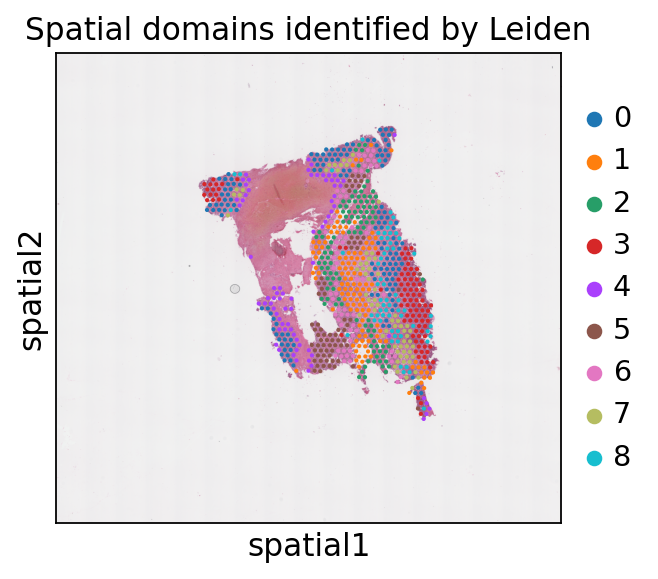

In [11]:
alpha = 0.4 # 40% weight is given to spatial proximity

joint_graph = (1 - alpha) * nn_graph_genes + alpha * nn_graph_space  # weighed sum of the two neigborhood graphs

# Perform Leiden clustering using the joint graph
sc.tl.leiden(adata_st, adjacency=joint_graph, key_added="squidpy_domains")
# plot squidpy spatial domains
sq.pl.spatial_scatter(adata_st, color="squidpy_domains", title="Spatial domains identified by Leiden")

In [12]:
#adata_st.uns.pop('squidpy_domains_colors')  #run if you want to clean squidpy_domains

Q9. Compare the inferred spatial domains with spatial deconvolution results (cell-type proportions). Do you notice any common patterns?

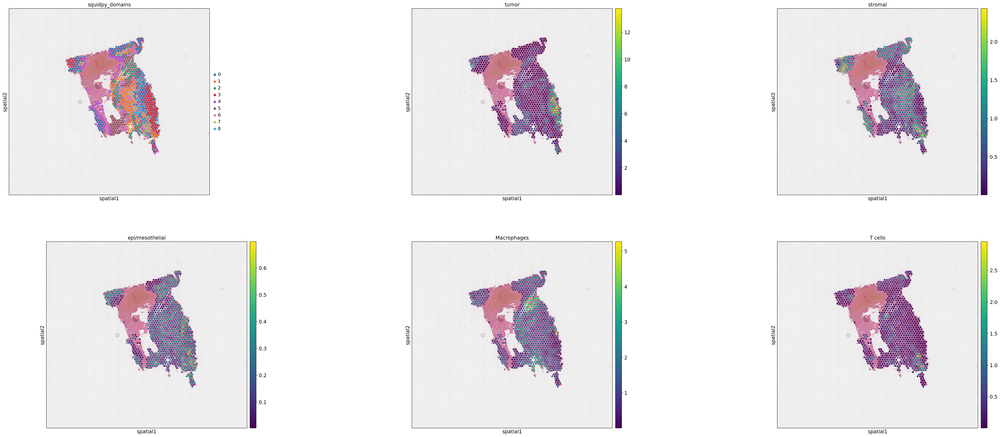

In [13]:
# Select cell populations and spatial domains
features = ["squidpy_domains", # Leiden domains
            "tumor", "stromal", "epi/mesothelial", "Macrophages", "T cells"] # estimated abundance of different cell populations

sq.pl.spatial_scatter(adata_st, color=features, figsize=(14, 10), ncols=3)

***Bonus***: Quantify cell-type composition within each spatial domain - plot a heatmap

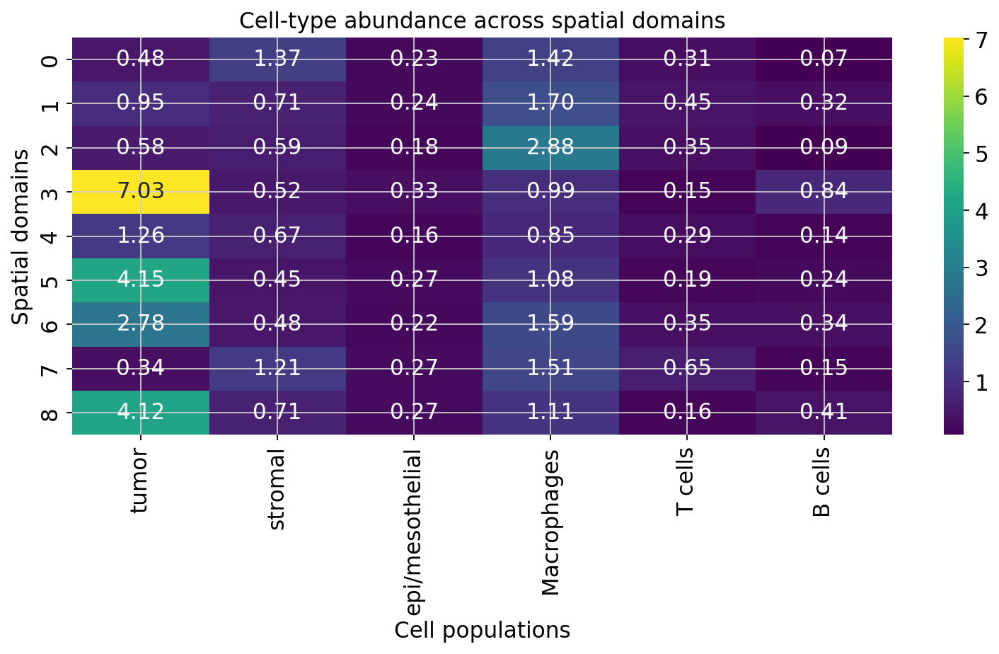

In [14]:
# Bonus:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Cell populations of interest
cell_types = [
    "tumor",
    "stromal",
    "epi/mesothelial",
    "Macrophages",
    "T cells",
    "B cells"
]

# Combine spatial domains and cell-type abundance estimates
df = adata_st.obs[["squidpy_domains"] + cell_types].copy()

# Calculate mean abundance per spatial domain
domain_composition = df.groupby("squidpy_domains", observed=True)[cell_types].mean()

# Visualize
plt.figure(figsize=(10, 6))
sns.heatmap(
    domain_composition,
    cmap="viridis",
    annot=True,
    fmt=".2f"
)

plt.xlabel("Cell populations")
plt.ylabel("Spatial domains")
plt.title("Cell-type abundance across spatial domains")
plt.tight_layout()
plt.show()

# Spatial domains identified by Leiden clustering show correspondence with the spatial distribution of cell-type abundance estimates.
# Some domains may be enriched in tumor cells, whereas others may display higher stromal or immune-cell abundance.
# This suggests that the identified spatial domains reflect distinct cellular and potentially functional compartments within the tumor microenvironment.

### Identifying spatially variable genes (SVGs)

Q10. Identify spatially variable genes using Moran's I statistic using graph module of squidpy: sq.gr.spatial_autocorr(). We will restrain the analysis to the set of highly variable genes.

In [15]:
# subset HVG 
HVG_names = adata_st[:,adata_st.var.highly_variable].var_names

sq.gr.spatial_autocorr(adata_st, mode="moran", genes=HVG_names) #Moran's I measures spatial autocorrelation, i.e. whether neighbouring spots tend to have similar gene expression levels

#Positive Moran's I: spatial clustering of similar expression values (potentially spatially enriched genes).
#Moran's I close to zero: expression is spatially random.
#Negative Moran's I: neighbouring spots tend to have dissimilar expression values.

Calculating moran's statistic for `None` permutations using `1` core(s)
Adding `adata.uns['moranI']`
Finish (0:00:00)


Q11. Print the results and plot spatial expression of the top SVGs. Compare with the top HVGs. 

                 I  pval_norm  var_norm  pval_norm_fdr_bh
gene_ids                                                 
PRG4      0.812025        0.0  0.000483               0.0
TSPAN3    0.796462        0.0  0.000483               0.0
NABP1     0.793860        0.0  0.000483               0.0
SLC39A8   0.793563        0.0  0.000483               0.0
CYBRD1    0.793527        0.0  0.000483               0.0
OLFML1    0.786241        0.0  0.000483               0.0
MSLN      0.777154        0.0  0.000483               0.0
STEAP4    0.776480        0.0  0.000483               0.0
RSPO1     0.773775        0.0  0.000483               0.0
CLU       0.773093        0.0  0.000483               0.0


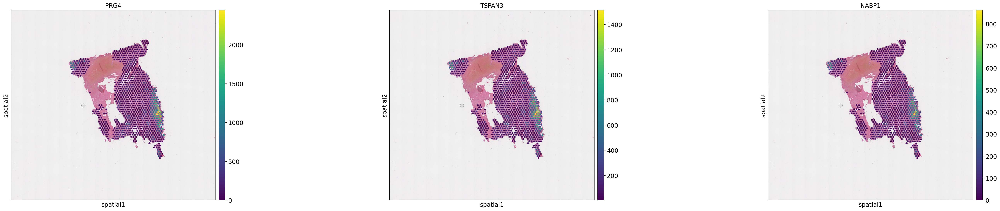

In [16]:
print(adata_st.uns["moranI"].head(10))

sq.pl.spatial_scatter(adata_st, color=["PRG4", "TSPAN3", "NABP1"], figsize=(12, 8), ncols=4)

Are they expressed in the same area? If so, probably you computed the Moran's I on the raw counts, and it just highlighed the area with the highest expression (see Question 3).  
It is recommended to use normalized counts to find the SVGs. You may need to recompute the Moran's I on the log-transformed data (stored in .layers) 

Calculating moran's statistic for `None` permutations using `1` core(s)
Adding `adata.uns['moranI']`
Finish (0:00:00)
                 I  pval_norm  var_norm  pval_norm_fdr_bh
gene_ids                                                 
PRG4      0.812025        0.0  0.000483               0.0
TSPAN3    0.796462        0.0  0.000483               0.0
NABP1     0.793860        0.0  0.000483               0.0
SLC39A8   0.793563        0.0  0.000483               0.0
CYBRD1    0.793527        0.0  0.000483               0.0
OLFML1    0.786241        0.0  0.000483               0.0
MSLN      0.777154        0.0  0.000483               0.0
STEAP4    0.776480        0.0  0.000483               0.0
RSPO1     0.773775        0.0  0.000483               0.0
CLU       0.773093        0.0  0.000483               0.0
                 I  pval_norm  var_norm  pval_norm_fdr_bh
gene_ids                                                 
FOSB      0.835460        0.0  0.000483               0.0
CTSL      0.

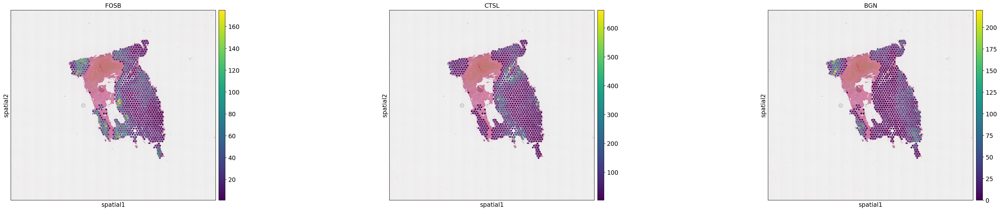

In [17]:
# Recompute Moran's I using normalized expression
moranI_raw = adata_st.uns["moranI"].copy() # if we want to store the previous results
sq.gr.spatial_autocorr(adata_st, genes=HVG_names, mode="moran", layer = "log1p_norm") # re-compute the Moran Indexes
print(moranI_raw.head(10))
moranI_norm = adata_st.uns["moranI"]
print(moranI_norm.head(10))

comparison = pd.DataFrame({
    "Moran_I_raw": moranI_raw["I"],
    "Moran_I_norm": moranI_norm["I"]
})

comparison = comparison.sort_values(
    "Moran_I_norm",
    ascending=False
)

print(comparison.head(10))

sq.pl.spatial_scatter(adata_st, color=["FOSB", "CTSL", "BGN"], figsize=(12, 8), ncols=4)

### Neighborhood analysis  

After identification of spatial domains we can quantify the spatial enrichment of the obtained clusters.  

Neighborhood enrichment quantifies how often two clusters occur near each other in space.
If cells or spots from one cluster are frequently located next to those from another cluster, the pair receives a high enrichment score, indicating spatial enrichment.
On the other hand, if the two clusters rarely appear as neighbors, they tend to be spatially separated — the enrichment score is low, indicating spatial depletion.

Calculating neighborhood enrichment using `1` core(s)


  0%|          | 0/1000 [00:00<?, ?/s]

Adding `adata.uns['squidpy_domains_nhood_enrichment']`
Finish (0:00:00)


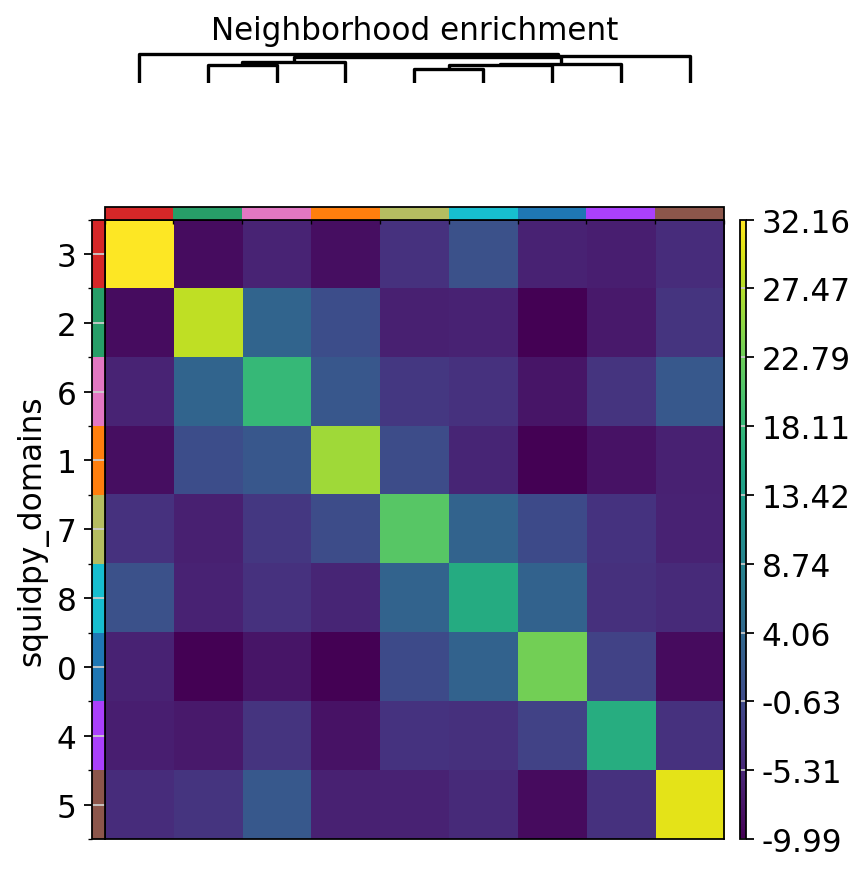

In [18]:
#sq.gr.spatial_neighbors(adata_st)
sq.gr.nhood_enrichment(adata_st, cluster_key="squidpy_domains")
sq.pl.nhood_enrichment(adata_st, cluster_key="squidpy_domains", method="average", figsize=(5, 5))


### Cell-cell interaction inference

In this section, we will infer cell-cell interactions between cell types and spatial regions. We will start by using LIANA+ framework that combines various inference methods and LR ressources.  
See documentation and tutorials at LIANA+ web page: https://liana-py.readthedocs.io/en/latest/api.html 

#### 1. CCI inference from annotated scRNA-seq data (dissociated cells). 

Q12. Load the annotated single-cell data from the previous TP.

In [20]:
adata_sc = sc.read("/data/Training-MG/files/data/Practical1/scRNAseq/2026/annotated/sample3B_annotation_level2.h5ad")

Cell–cell signalling is inferred between pairs of cell groups, defined as source and target populations of cells.  
To perform this analysis, you have to provide annotations that assign each cell to one of these groups.  In single-cell datasets, these groups typically correspond to the identified cell types.

Q13. Explore the loaded data. How many cells and features it has? Check the cell type annotations ("annotation_level2" column).

In [26]:
# Overview of the object
print(adata_sc)

# Number of cells and genes
print("\nNumber of cells:", adata_sc.n_obs)
print("Number of genes/features:", adata_sc.n_vars)

# Check that the annotation column exists
print("\nAvailable obs columns:")
print(adata_sc.obs.columns.tolist())

# Inspect the cell-type annotations
print("\nInspect the cell-type annotations:")
print(adata_sc.obs["annotation_level2"].head())

# Number of cells in each annotated cell type
print("\nNumber of cells in each annotated cell type:")
cell_type_counts = adata_sc.obs["annotation_level2"].value_counts()
print(cell_type_counts)

# Relative abundance of each cell type
print("\nRelative abundance of each cell type:")
cell_type_proportions = cell_type_counts / cell_type_counts.sum()
print(cell_type_proportions)

AnnData object with n_obs × n_vars = 8933 × 36601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'mt_outlier', 'is_outlier', 'sample', 'scDblFinder_score', 'scDblFinder_class', 'leiden_res0.05', 'leiden_res0.1', 'leiden_res0.15', 'leiden_res0.25', 'leiden_res0.5', 'leiden_res0.75', 'leiden_res1.0', 'predicted_labels_level1', 'annotation_level1', 'annotation_level1_conf_score', 'is_tumor', 'annotation_level2', 'annotation_level2_conf_score', 'annotation_BAP1', 'annotation_CDKN2_MTAP', 'annotation_TP53', 'annotation_NF2', 'annotation_EZH2'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total

Q14. Run rank_aggregated method from li.mt on single-cell log-normalised counts, with "consensus" resource and cell-type annotations.

In [27]:
# methods available in liana
li.method.show_methods()

,Method Name,Magnitude Score,Specificity Score,Reference
0,CellPhoneDB,lr_means,cellphone_pvals,"Efremova, M., Vento-Tormo, M., Teichmann, S.A...."
0,Connectome,expr_prod,scaled_weight,"Raredon, M.S.B., Yang, J., Garritano, J., Wang..."
0,log2FC,None,lr_logfc,"Dimitrov, D., Türei, D., Garrido-Rodriguez, M...."
0,NATMI,expr_prod,spec_weight,"Hou, R., Denisenko, E., Ong, H.T., Ramilowski,..."
0,SingleCellSignalR,lrscore,None,"Cabello-Aguilar, S., Alame, M., Kon-Sun-Tack, ..."
0,Rank_Aggregate,magnitude_rank,specificity_rank,"Dimitrov, D., Türei, D., Garrido-Rodriguez, M...."
0,Geometric Mean,lr_gmeans,gmean_pvals,CellPhoneDBv2's permutation approach applied t...
0,scSeqComm,inter_score,None,"Baruzzo, G., Cesaro, G., Di Camillo, B. 2022. ..."
0,CellChat,lr_probs,cellchat_pvals,"Jin, S., Guerrero-Juarez, C.F., Zhang, L., Cha..."


In [28]:
# rank aggregate
# run LIANA+’s rank_aggregate on the log-normalized single-cell expression matrix, 
# using annotation_level2 to define source and target cell types and the consensus ligand–receptor resource
li.mt.rank_aggregate(
    adata_sc,
    groupby="annotation_level2",
    resource_name="consensus",
    layer="log1p_norm",
    use_raw=False,
    expr_prop=0.1,
    verbose=True
)

Using resource `consensus`.
Using the `log1p_norm` layer!
10142 features of mat are empty, they will be removed.
/home/delhommet/miniconda3/envs/MG_sc_env/lib/python3.10/site-packages/liana/method/_pipe_utils/_pre.py:164: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
/home/delhommet/miniconda3/envs/MG_sc_env/lib/python3.10/site-packages/liana/method/_pipe_utils/_pre.py:167: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
0.11 of entities in the resource are missing from the data.


Generating ligand-receptor stats for 8933 samples and 1648 features


/home/delhommet/miniconda3/envs/MG_sc_env/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
/home/delhommet/miniconda3/envs/MG_sc_env/lib/python3.10/site-packages/liana/method/sc/_liana_pipe.py:288: ImplicitModificationWarning: Setting element `.layers['scaled']` of view, initializing view as actual.


Assuming that counts were `natural` log-normalized!
Running CellPhoneDB


100%|██████████| 1000/1000 [00:10<00:00, 97.82it/s]


Running Connectome
Running log2FC
Running NATMI
Running SingleCellSignalR


Q15. Print the obtained results. Sort the values by the magnitude_rank column (rank by the strength of the signal).

In [30]:
liana_res = adata_sc.uns["liana_res"]

top_interactions = (
    liana_res
    .sort_values("magnitude_rank", ascending=True)
    [["source", "target", "ligand_complex", "receptor_complex",
      "magnitude_rank", "specificity_rank"]]
    .head(20)
)

top_interactions

,source,target,ligand_complex,receptor_complex,magnitude_rank,specificity_rank
25161,stromal,stromal,TIMP1,CD63,9.886749e-09,0.040881
25752,stromal,tumor,TIMP1,CD63,3.954612e-08,0.071970
24206,stromal,epi/mesothelial,TIMP1,CD63,2.471469e-07,0.081074
8327,Monocytes,Macrophages,S100A9,CD68,8.006850e-07,0.000421
9683,Monocytes,stromal,TIMP1,CD63,9.884783e-07,0.073652
8328,Monocytes,Macrophages,S100A9,ITGB2,2.530169e-06,0.000890
23453,stromal,endothelial,TIMP1,CD63,3.567697e-06,0.124357
18077,epi/mesothelial,pDC,MIF,CD74_CXCR4,4.358129e-06,0.132315
10075,T cells,ILC,B2M,KLRD1,4.782966e-06,0.021871
22303,stromal,Macrophages,TIMP1,CD63,5.227548e-06,0.128934


Q16. Make a dotplot of the aggregated interaction scores (magnitude_rank). You can provide specific cell types as source and target groups.


Source labels in LIANA results:
['B cells', 'DC', 'ILC', 'Macrophages', 'Monocytes', 'T cells', 'endothelial', 'epi/mesothelial', 'pDC', 'stromal', 'tumor']

Target labels in LIANA results:
['B cells', 'DC', 'ILC', 'Macrophages', 'Monocytes', 'T cells', 'endothelial', 'epi/mesothelial', 'pDC', 'stromal', 'tumor']


/home/delhommet/miniconda3/envs/MG_sc_env/lib/python3.10/site-packages/liana/plotting/_common.py:98: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


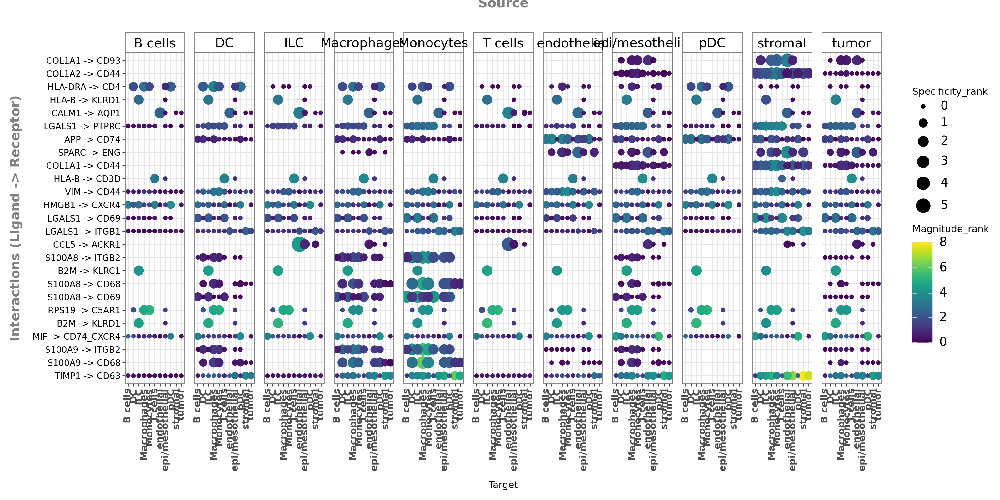

In [37]:
# Cell types available as interaction sources
print("\nSource labels in LIANA results:")
print(sorted(adata_sc.uns["liana_res"]["source"].unique()))

# Cell types available as interaction targets
print("\nTarget labels in LIANA results:")
print(sorted(adata_sc.uns["liana_res"]["target"].unique()))


li.pl.dotplot(
    adata_sc,
    colour="magnitude_rank",
    size="specificity_rank",
    inverse_colour=True,
    inverse_size=True,
    source_labels=['B cells', 'DC', 'ILC', 'Macrophages', 'Monocytes', 'T cells', 'endothelial', 'epi/mesothelial', 'pDC', 'stromal', 'tumor'],
    target_labels=['B cells', 'DC', 'ILC', 'Macrophages', 'Monocytes', 'T cells', 'endothelial', 'epi/mesothelial', 'pDC', 'stromal', 'tumor'],
    top_n=25,
    orderby="magnitude_rank",
    orderby_ascending=True,
    figure_size=(16, 8)
)

Q17. Plot spatial expression of some ligand-receptor pairs with high lrscore. Are they spatially co-localised?

In [38]:
# select a few top LIANA+ interactions, then plot the ligand and receptor genes separately in the Visium object using log-normalized expression
# Retrieve LIANA+ results
liana_res = adata_sc.uns["liana_res"]

# Select top interactions by strength
top_interactions = (
    liana_res
    .sort_values("magnitude_rank", ascending=True)
    [["source", "target", "ligand_complex", "receptor_complex",
      "magnitude_rank", "specificity_rank"]]
    .head(10)
)

top_interactions

,source,target,ligand_complex,receptor_complex,magnitude_rank,specificity_rank
25161,stromal,stromal,TIMP1,CD63,9.886749e-09,0.040881
25752,stromal,tumor,TIMP1,CD63,3.954612e-08,0.071970
24206,stromal,epi/mesothelial,TIMP1,CD63,2.471469e-07,0.081074
8327,Monocytes,Macrophages,S100A9,CD68,8.006850e-07,0.000421
9683,Monocytes,stromal,TIMP1,CD63,9.884783e-07,0.073652
8328,Monocytes,Macrophages,S100A9,ITGB2,2.530169e-06,0.000890
23453,stromal,endothelial,TIMP1,CD63,3.567697e-06,0.124357
18077,epi/mesothelial,pDC,MIF,CD74_CXCR4,4.358129e-06,0.132315
10075,T cells,ILC,B2M,KLRD1,4.782966e-06,0.021871
22303,stromal,Macrophages,TIMP1,CD63,5.227548e-06,0.128934


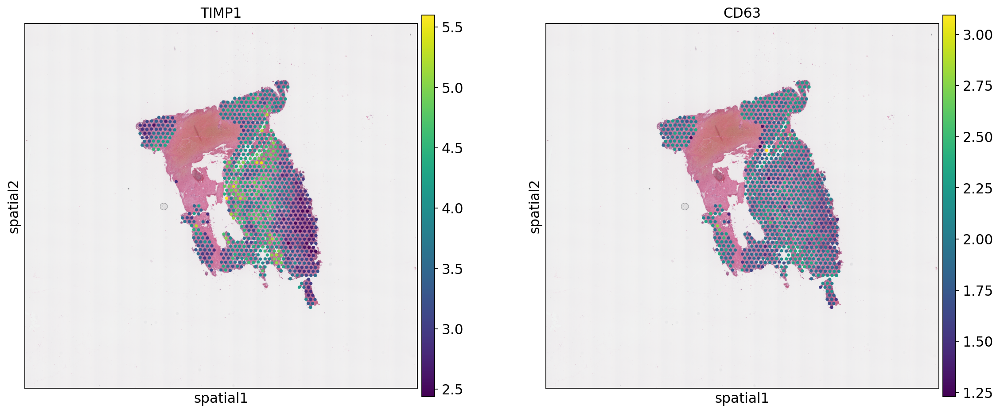

In [44]:
ligand = "TIMP1"
receptor = "CD63"

sq.pl.spatial_scatter(
    adata_st,
    color=[ligand, receptor],
    layer="log1p_norm", #rather than raw counts, because raw-count maps can mainly reflect sequencing depth rather than a biologically meaningful spatial pattern
    figsize=(7, 7),
    ncols=2
)

Q18 (optional). Plot a cell-cell interaction network with cell types in the nodes and aggregated score to compute the weights of the edges.

<Axes: >

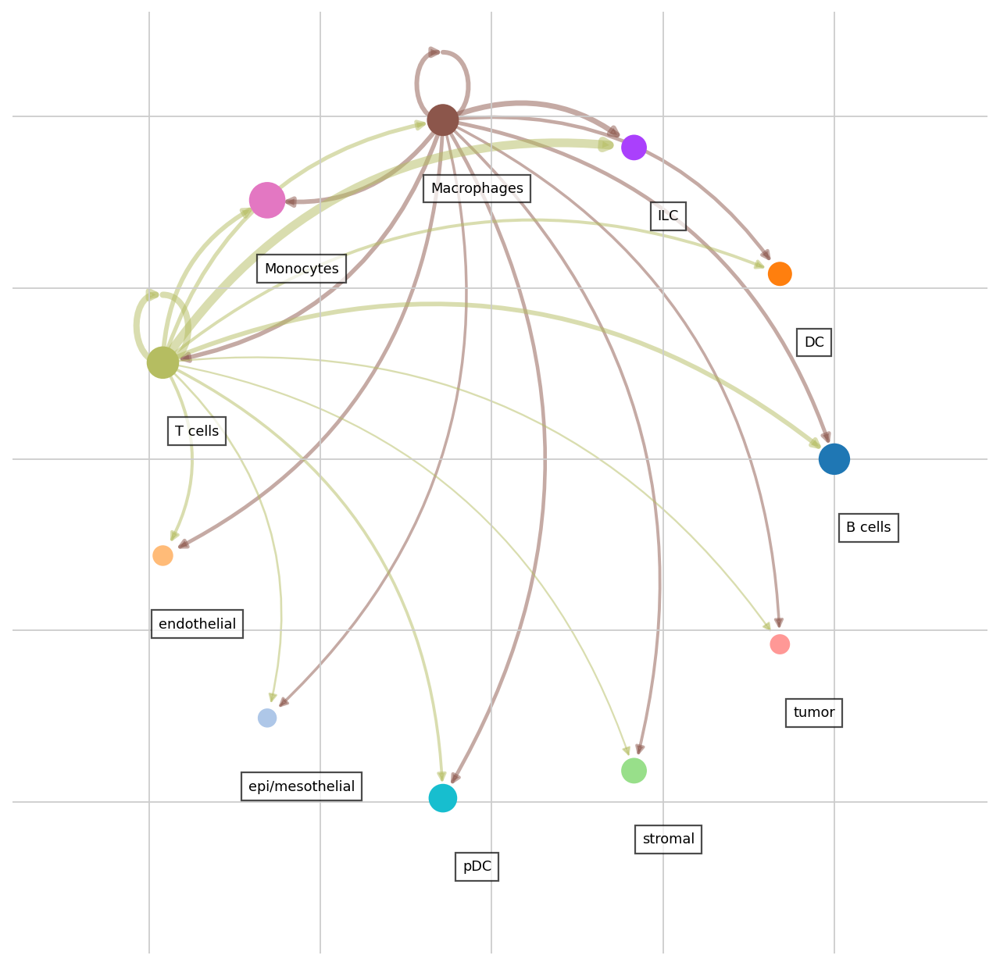

In [49]:
li.pl.circle_plot(adata_sc,
                  groupby="annotation_level2",
                  score_key="magnitude_rank",
                  inverse_score=True,
                  source_labels=["Macrophages","T cells"],
                  filter_fun=lambda x: x['specificity_rank'] <= 0.05,
                  pivot_mode='mean',  # or "count" to weight by the number of interactions
                  figure_size=(10, 10),
                  )

# How to read the network
#Node: A cell type from annotation_level2
#Directed edge: Candidate communication from a source cell type to a target cell type
#Edge thickness/weight: Number of ligand–receptor interactions passing the specificity filter (pivot_mode="count")
#Edge color: Aggregated magnitude_rank; because inverse_score=True, stronger interactions are emphasized
#Arrow direction: Ligand-producing source → receptor-expressing target

Q19 (optional): Prioritize a spatially supported cell–cell interaction

Choose one LIANA+ interaction involving tumor cells. Using the spatial expression of its ligand and receptor and the deconvoluted cell-type proportions, decide whether the interaction is spatially plausible. Explain what additional evidence would be needed to validate it.

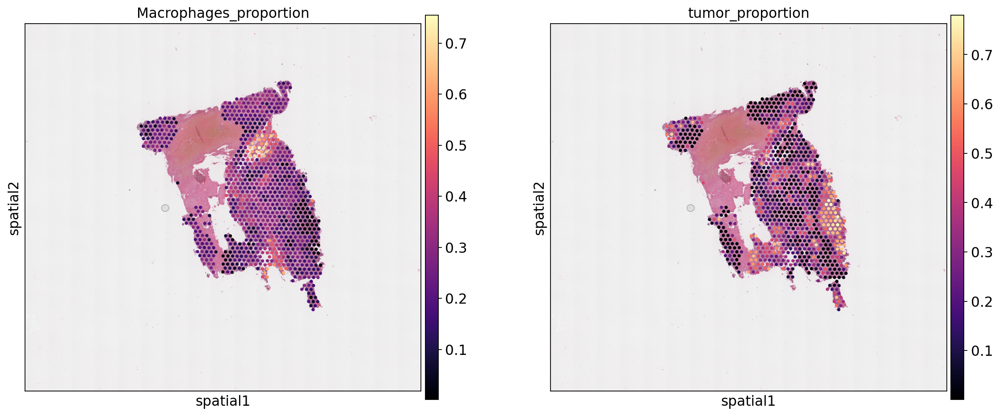

In [58]:
# Retrieve the mean cell2location abundance estimates
deconv = adata_st.obsm["means_cell_abundance_w_sf"]

# Convert estimated abundances to proportions per spot
deconv_prop = deconv.div(deconv.sum(axis=1), axis=0)

# Exact column names
source_cell_type = "meanscell_abundance_w_sf_Macrophages"
target_cell_type = "meanscell_abundance_w_sf_tumor"

# Add proportions to adata_st.obs
adata_st.obs["Macrophages_proportion"] = deconv_prop[source_cell_type]
adata_st.obs["tumor_proportion"] = deconv_prop[target_cell_type]

# Plot the macrophage and tumor abundance maps
sq.pl.spatial_scatter(
    adata_st,
    color=[
        "Macrophages_proportion",
        "tumor_proportion"
    ],
    figsize=(7, 7),
    ncols=2,
    cmap="magma"
)